<a href="https://colab.research.google.com/github/njonjoann12-sys/Class_Project_2/blob/main/Building_my_First_Supervised_Machine_Learning_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Target/output and features**

The dataset from the geothermal pipeline experiment was used to develop a supervised learning model for predicting measured heat transfer. The target variable was measured heat transfer (W), while the input features were inlet temperature (°C) and outlet temperature (°C). These features were selected because pipeline temperatures are relevant to heat-transfer behaviour.

**Determine the type of problem**

This is a regression problem because the target variable, measured heat transfer, is a continuous numerical value. The objective is to predict the magnitude of heat transfer from the input temperatures rather than assign observations to predefined categories, as would be required in a classification problem.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Experimental_and_modelling_Data-Ex_Setup.xlsx to Experimental_and_modelling_Data-Ex_Setup.xlsx


In [3]:
import pandas as pd

file_name = 'Experimental_and_modelling_Data-Ex_Setup.xlsx'

pipeline = pd.read_excel(file_name, sheet_name='PipelineStepChange')
heat = pd.read_excel(file_name, sheet_name='GroundHeatTrasnfer')

print("Pipeline data:", pipeline.shape)
print("Heat transfer data:", heat.shape)

display(pipeline.head())
display(heat.head())


Pipeline data: (759, 9)
Heat transfer data: (759, 5)


,Measured and predicted outlet temperatures by the numerical models for the experiment of the step change to the buried pipe,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Time (h),Inlet Temperature- Measured (Cº),Outlet Temperature- Measured (Cº),3D model- OpenFOAM (Cº),DTN model (Cº),Combined DTN-PFST model (Cº),Error (3D model),Error (DTN model),Error (Combined DTN-PFST model)
2,0,38.15833,16.35428,17.8176,16.8176,16.99984,-1.46332,-0.46332,-0.64556
3,0.05556,38.23205,35.32343,35.5646,35.65434,33.54345,-0.24117,-0.33091,1.77998
4,0.11111,38.52088,35.55219,35.6427,35.21056,33.38371,-0.09051,0.34163,2.16848


,Measured and calculated ground surface heat transfer for the case of the step change to the buried pipe.,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,Time (h),Measured heat transfer (W),3D model-OpenFOAM (W),DTN model (W),Combined DTN-PFST (W)
2,0,0,0,0,0
3,0.05556,3.98535,6.19048,3.98535,2.04377
4,0.11111,5.78131,5.78964,3.35239,4.31478


In [8]:
# Use row index 2 as the header
pipeline = pd.read_excel(
    file_name,
    sheet_name='PipelineStepChange',
    header=2
)

heat = pd.read_excel(
    file_name,
    sheet_name='GroundHeatTrasnfer',
    header=2
)

# Select and rename the required columns
pipeline_data = pipeline[
    [
        'Time (h)',
        'Inlet Temperature- Measured (Cº)',
        'Outlet Temperature- Measured (Cº)'
    ]
].copy()

pipeline_data.columns = [
    'Time (h)',
    'Inlet Temperature (C)',
    'Outlet Temperature (C)'
]

heat_data = heat[
    ['Time (h)', 'Measured heat transfer (W)']
].copy()

heat_data = heat_data.rename(columns={
    'Measured heat transfer (W)': 'Measured Heat Transfer (W)'
})

# Combine using time
df = pd.merge(
    pipeline_data,
    heat_data,
    on='Time (h)',
    how='inner',
    validate='one_to_one'
)

df = df.dropna().reset_index(drop=True)

print("Dataset dimensions:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
display(df.head())




Dataset dimensions: (757, 4)

Missing values:
Time (h)                      0
Inlet Temperature (C)         0
Outlet Temperature (C)        0
Measured Heat Transfer (W)    0
dtype: int64


,Time (h),Inlet Temperature (C),Outlet Temperature (C),Measured Heat Transfer (W)
0,0.00000,38.15833,16.35428,0.00000
1,0.05556,38.23205,35.32343,3.98535
2,0.11111,38.52088,35.55219,5.78131
3,0.16667,38.18224,36.57940,5.78131
4,0.22222,38.23650,36.32526,10.09823


In [9]:
from sklearn.model_selection import train_test_split

features = [
    'Inlet Temperature (C)',
    'Outlet Temperature (C)'
]
target = 'Measured Heat Transfer (W)'

X = df[features]
y = df[target]

# Chronological 80:20 split
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 605
Testing samples: 152


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf_model.fit(X_train, y_train)

# Predict on the test set
linear_predictions = linear_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

print("Both models trained successfully.")
print("Linear Regression predictions:", len(linear_predictions))
print("Random Forest predictions:", len(rf_predictions))


Both models trained successfully.
Linear Regression predictions: 152
Random Forest predictions: 152


In [11]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true, predictions):
    return {
        'MAE (W)': mean_absolute_error(y_true, predictions),
        'RMSE (W)': np.sqrt(mean_squared_error(y_true, predictions)),
        'R²': r2_score(y_true, predictions)
    }

comparison = pd.DataFrame({
    'Linear Regression': evaluate_model(y_test, linear_predictions),
    'Random Forest': evaluate_model(y_test, rf_predictions)
}).T

display(comparison.round(4))

,MAE (W),RMSE (W),R²
Linear Regression,10.8548,11.2482,-67.6064
Random Forest,3.9834,4.3799,-9.4023


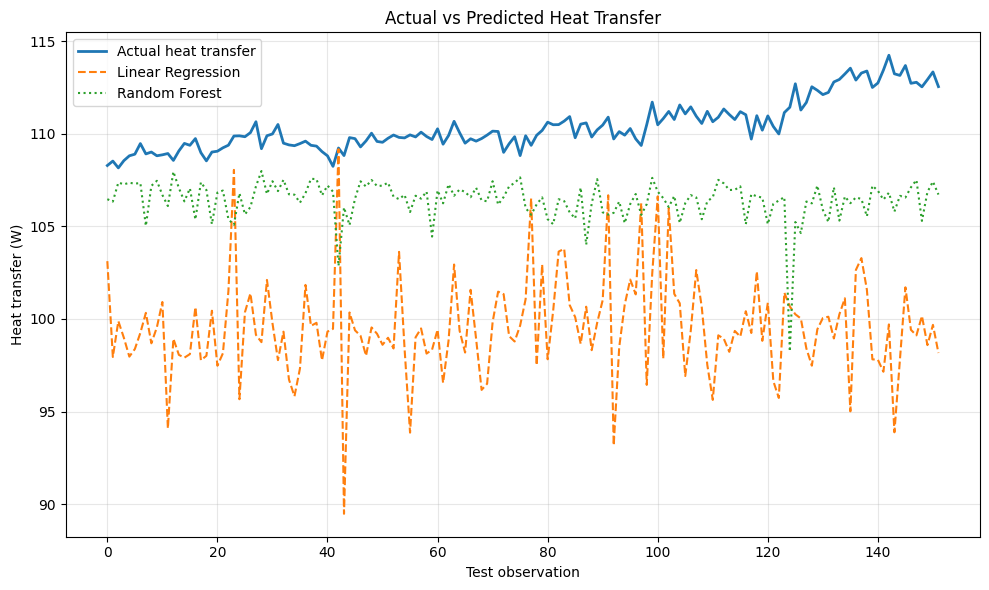

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(y_test.values, label='Actual heat transfer', linewidth=2)
plt.plot(linear_predictions, label='Linear Regression', linestyle='--')
plt.plot(rf_predictions, label='Random Forest', linestyle=':')

plt.xlabel('Test observation')
plt.ylabel('Heat transfer (W)')
plt.title('Actual vs Predicted Heat Transfer')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Results and Discussion**

The performance of Linear Regression and Random Forest Regression was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (\(R^2\)).

The results indicate that Random Forest Regression outperformed Linear Regression across all three evaluation metrics. Random Forest achieved an MAE of 3.9834 W and an RMSE of 4.3799 W, compared with 10.8548 W and 11.2482 W, respectively, for Linear Regression. This represents a reduction of approximately 63.3% in MAE and 61.1% in RMSE.

However, both models produced negative \(R^2\) values. This indicates that their predictions performed worse than a baseline that predicts the mean heat transfer of the test dataset. The particularly low \(R^2\) values suggest that the selected input features may not adequately explain variations in measured heat transfer during the test period.

The chronological train-test split may also have contributed to the poor performance because the relationship between the input temperatures and heat transfer may change over time. Additional features, such as flow rate, ambient temperature, and pipeline operating conditions, could improve predictive performance.

**Conclusion**

Random Forest Regression was the better-performing model for this dataset because it achieved lower MAE and RMSE values and a less negative \(R^2\) value than Linear Regression. However, neither model demonstrated satisfactory predictive performance on the test dataset. Further investigation and model refinement are therefore necessary before either model can be considered reliable for predicting geothermal pipeline heat transfer.